In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score
from sklearn.metrics import auc

In [2]:
sample = pd.read_parquet('criteo_sample_5pct.parquet')

In [3]:
sample.shape

(698980, 16)

In [4]:
sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 698980 entries, 0 to 698979
Data columns (total 16 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   f0          698980 non-null  float32
 1   f1          698980 non-null  float32
 2   f2          698980 non-null  float32
 3   f3          698980 non-null  float32
 4   f4          698980 non-null  float32
 5   f5          698980 non-null  float32
 6   f6          698980 non-null  float32
 7   f7          698980 non-null  float32
 8   f8          698980 non-null  float32
 9   f9          698980 non-null  float32
 10  f10         698980 non-null  float32
 11  f11         698980 non-null  float32
 12  treatment   698980 non-null  int8   
 13  conversion  698980 non-null  int8   
 14  visit       698980 non-null  int8   
 15  exposure    698980 non-null  int8   
dtypes: float32(12), int8(4)
memory usage: 34.7 MB


In [5]:
sample.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,18.068092,10.059654,8.873258,1.815324,10.280525,4.115453,-7.822229,4.833815,3.783884,13.190056,5.300375,-0.168679,0,0,0,0
1,24.590458,10.059654,8.214383,4.679882,10.280525,4.115453,-3.282109,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
2,22.693071,10.059654,8.214383,4.679882,10.280525,4.115453,-3.282109,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,25.773638,10.059654,8.968005,4.679882,11.561050,4.115453,-2.411115,4.833815,3.847294,13.190056,6.356286,-0.168679,0,0,0,0
4,12.616364,10.059654,8.412100,4.679882,10.280525,4.115453,0.294443,4.833815,3.943716,18.380112,5.300375,-0.168679,0,0,0,0


### Research Question

Given a fixed marketing budget, which customers should be targeted to maximize incremental conversions, rather than simply targeting customers who are most likely to purchase?


### Project Objectives

**1.** Predict how much each customer's behavior is expected to change because of the marketing treatment.

**2.** Target customers with the highest expected incremental conversion.

### Key Variables

- **Dependent Variable**: conversion
- **Treatment Variable**: treatment
- **Features**: f0–f11

`treatment = 1` means the customer was *randomly assigned* to the campaign. It does not mean they actually saw an ad (that is the `exposure` column). So the effects I estimate are the effects of *being targeted*, also called intention-to-treat (ITT) effects. I will also estimate the effect of *actually seeing the ad*.

In [6]:
features = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']

### 1. Data Validation Checks

- First, I look at the share of customers in the treatment group and compare the conversion, visit, and exposure rates between the treatment and control groups.

In [7]:
print('Share of customers in treatment group:', sample['treatment'].mean())

sample.groupby('treatment')[['conversion', 'visit', 'exposure']].mean()

Share of customers in treatment group: 0.85


,conversion,visit,exposure
treatment,,,
0,0.002012,0.037664,0.000000
1,0.003147,0.048459,0.036315


- The treatment group contains 85% of customers. Both conversion and visit rates are higher in the treatment group, while exposure occurs only among treated customers.
    1. 85% of customers are in the treatment group and 15% are in the control group.
    2. The conversion rate is 0.20% for the control group and 0.31% for the treatment group.
    3. The visit rate is 3.77% for the control group and 4.85% for the treatment group.
    4. The exposure rate is 0% for the control group and 3.63% for the treatment group.

- Nobody in the control group should have seen an ad, so this should print 0.

In [8]:
control_group = sample[sample['treatment'] == 0]

print('Exposed customers in control group:', control_group['exposure'].sum())

Exposed customers in control group: 0


- Next, I check whether the two groups of customers are similar using the **standardized mean difference (SMD)** for each feature.

  **SMD = (mean in group 1 − mean in group 0) / average standard deviation**

* Dividing by the standard deviation puts the features on a common scale, making them easier to compare. A common rule of thumb is that an **absolute SMD below 0.1** indicates good balance between the groups.

In [9]:
def standardized_mean_difference(data, group_column, columns):
    group_1 = data[data[group_column] == 1][columns]
    group_0 = data[data[group_column] == 0][columns]

    difference_in_means = group_1.mean() - group_0.mean()
    average_std = np.sqrt((group_1.var() + group_0.var()) / 2)

    return difference_in_means / average_std

- For each feature, the function measures how different the treatment and control groups are, relative to the amount of variation in that feature.
- I compare two groups:
  1. **Treatment vs. control:** Since treatment was randomly assigned, these two groups should look similar, so the SMDs should be close to 0.
  2. **Exposed vs. unexposed customers within the treatment group:** Seeing an ad was not random, so these customers may be quite different from each other. This is why I can't simply use the unexposed treated customers as the control group.

In [10]:
treatment_group = sample[sample['treatment'] == 1]

balance = pd.DataFrame({
    'treatment vs control': standardized_mean_difference(sample, 'treatment', features),
    'exposed vs unexposed (treated only)': standardized_mean_difference(treatment_group, 'exposure', features),
})

balance.round(3)

,treatment vs control,exposed vs unexposed (treated only)
f0,-0.006,-0.860
f1,0.023,0.424
f2,-0.011,0.028
f3,-0.053,-1.472
f4,0.009,0.466
f5,-0.030,-0.644
f6,-0.040,-1.395
f7,0.023,0.596
f8,-0.020,-0.999
f9,0.025,0.875


- The treatment and control groups are well balanced: all SMDs are below 0.1 in absolute value. This is what we would expect because treatment was randomly assigned.
- In contrast, several SMDs are much larger when comparing exposed and unexposed customers within the treatment group. This suggests that seeing the ad was not random and that these customers differ in their characteristics. Therefore, I cannot simply use the unexposed treated customers as the control group.

### Average effect of being targeted and of seeing the ad

Since I cannot directly compare exposed and unexposed customers, I use the random assignment instead. Nobody in the control group saw an ad, so the difference in conversion rates between the treatment and control groups reflects the effect of targeting customers with the campaign. Dividing this difference by the share of treated customers who actually saw an ad gives the average effect of seeing the ad.


In [11]:
rates = sample.groupby('treatment')['conversion'].mean()
itt = rates[1] - rates[0]
exposure_rate = treatment_group['exposure'].mean()

print('Effect of being targeted (ITT):', itt)
print('Share of treated customers who saw an ad:', exposure_rate)
print('Effect of seeing the ad:', itt / exposure_rate)

Effect of being targeted (ITT): 0.0011349871717836464
Share of treated customers who saw an ad: 0.03631510116421744
Effect of seeing the ad: 0.03125386231615374


Being targeted increases the conversion rate by about 0.11 percentage points on average (0.31% vs. 0.20%).

* Only 3.63% of treated customers saw an ad. Among those customers, the estimated effect of seeing the ad is about 3.1 percentage points.
* This assumes that being assigned to the campaign affects conversion only through seeing an ad. The estimate applies to customers who saw an ad, not to all customers.
* The models in the rest of the notebook estimate the effect of being targeted, since that is what the company can control.


### Propensity score matching within the treatment group

The SMD table above already shows that exposure was not random. Here I look at the same question in a second way and then try to adjust for it.

* A **propensity score** is a customer's predicted chance of seeing an ad, based on their features.
* **Matching** pairs each exposed customer with an unexposed customer who has a similar propensity score, so that the two groups I compare look alike on the features.

I do this in five steps: (1) propensity model, (2) overlap, (3) matching, (4) balance after matching, and (5) comparison with the randomized estimate.

I only use `f0`–`f11`. `visit` and `conversion` happen after assignment, so they cannot be used to predict exposure.

This analysis does not change the uplift models below, which estimate the effect of being targeted.

**Step 1: Propensity model**

- I train a model that predicts `exposure` from the features. I use treated customers only, because nobody in the control group could be exposed.
- The predictions are **out-of-fold**: the data is split into five parts, and each customer's propensity comes from a model trained on the other four parts. This stops the model from simply memorizing who was exposed.
- I summarize the model with the **AUC**. This is the chance that the model gives a randomly chosen exposed customer a higher score than a randomly chosen unexposed customer.
    - If exposure were random, the features could not predict it and the AUC would be about 0.5.
    - An AUC of 1 would mean that exposure can be predicted perfectly from the features.

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors

treated = treatment_group.copy()

propensity_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=300,
    min_samples_leaf=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42
)

# Out-of-fold predictions: each customer's propensity comes from a model that did not see them
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

treated['propensity'] = cross_val_predict(
    propensity_model,
    treated[features],
    treated['exposure'],
    cv=folds,
    method='predict_proba'
)[:, 1]

print('Propensity model AUC:', roc_auc_score(treated['exposure'], treated['propensity']))

Propensity model AUC: 0.9200899871676036


**Result**

- The AUC is **0.92**. In 92% of exposed/unexposed pairs, the model gives the exposed customer the higher score.
- This is far above 0.5, so exposure was not random. Which customers saw an ad depends strongly on their features.

**Step 2: Overlap**

- Matching only works if, for each exposed customer, there are unexposed customers with a similar propensity. If the two groups had completely separate propensities, there would be nobody to match with.
- I plot the propensities of both groups on the **log-odds** scale, log(p / (1 − p)). Most propensities are very close to 0, so on the ordinary scale they would be squeezed together.

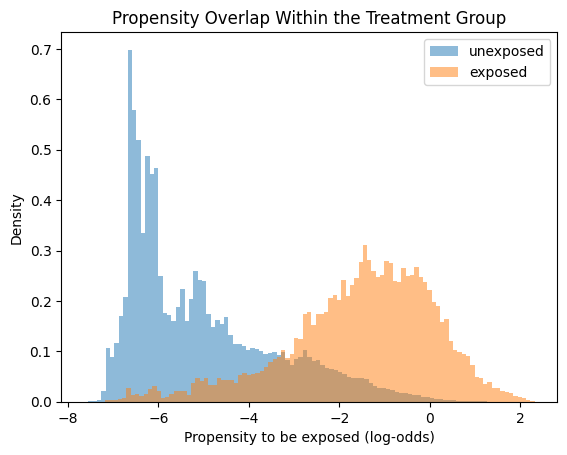

In [13]:
clipped = treated['propensity'].clip(1e-6, 1 - 1e-6)
treated['logit'] = np.log(clipped / (1 - clipped))

exposed = treated[treated['exposure'] == 1]
unexposed = treated[treated['exposure'] == 0]

plt.hist(unexposed['logit'], bins=100, density=True, alpha=0.5, label='unexposed')
plt.hist(exposed['logit'], bins=100, density=True, alpha=0.5, label='exposed')
plt.xlabel('Propensity to be exposed (log-odds)')
plt.ylabel('Density')
plt.title('Propensity Overlap Within the Treatment Group')
plt.legend()
plt.show()

**Result**

- The two groups sit in different places. Most unexposed customers are between −7 and −4 (a propensity below about 2%), while most exposed customers are between −3 and 1 (about 5% to 73%). This again shows that exposure was not random.
- The two distributions still overlap. The unexposed group looks thin on the right-hand side, but the chart shows shares, not counts. There are over 570,000 unexposed customers and 21,576 exposed customers, so even a thin tail contains many customers to match with.
- Unexposed customers are scarcest at the highest propensities, so I expect some of them to be matched more than once there.

**Step 3: Matching**

- For each exposed customer, I take the unexposed customer with the closest propensity on the log-odds scale (1 nearest neighbor).
- Matching is **with replacement**: one unexposed customer can be matched to several exposed customers. This gives closer matches in the regions where unexposed customers are scarce.
- I use a **caliper**: I drop exposed customers whose closest match is further away than 0.2 standard deviations of the log-odds propensity. This is a common rule of thumb to avoid poor matches. If many exposed customers were dropped, the matched estimate would only describe the ones that remain.

In [14]:
caliper = 0.2 * treated['logit'].std()

neighbors = NearestNeighbors(n_neighbors=1)
neighbors.fit(unexposed[['logit']])

distance, position = neighbors.kneighbors(exposed[['logit']])
distance = distance[:, 0]
position = position[:, 0]

within_caliper = distance <= caliper

matched_exposed = exposed[within_caliper]
matched_unexposed = unexposed.iloc[position[within_caliper]]

times_used = matched_unexposed.index.value_counts()

print('Exposed customers:', len(exposed))
print('Share matched within the caliper:', within_caliper.mean())
print('Different unexposed customers used:', len(times_used))
print('Most times one unexposed customer was used:', times_used.max())

Exposed customers: 21576
Share matched within the caliper: 1.0
Different unexposed customers used: 15784
Most times one unexposed customer was used: 36


**Result**

- All 21,576 exposed customers found a match within the caliper, so nobody was dropped. The matched estimate therefore describes all exposed customers, which is the same group as the ITT / exposure rate estimate.
- 15,784 different unexposed customers were used, so some were matched more than once (one of them 36 times). This reuse makes the estimate less precise, and I account for it in the standard error in Step 5.

**Step 4: Balance after matching**

- The purpose of matching is to make the two groups look alike on the features. To check whether it did, I reuse `standardized_mean_difference` on the matched pairs and put the result next to the SMDs from before matching.
- If matching worked, all SMDs should now be below 0.1 in absolute value.

In [15]:
matched = pd.concat([matched_exposed, matched_unexposed])

balance_matching = pd.DataFrame({
    'before matching': standardized_mean_difference(treated, 'exposure', features),
    'after matching': standardized_mean_difference(matched, 'exposure', features),
})

print('Largest absolute SMD after matching:', balance_matching['after matching'].abs().max())

balance_matching.round(3)

Largest absolute SMD after matching: 0.025854766368865967


,before matching,after matching
f0,-0.860,0.009
f1,0.424,0.023
f2,0.028,0.009
f3,-1.472,-0.005
f4,0.466,0.005
f5,-0.644,-0.026
f6,-1.395,-0.014
f7,0.596,0.004
f8,-0.999,-0.025
f9,0.875,0.021


**Result**

- Before matching, the SMDs were as large as −1.47 (`f3`) and −1.40 (`f6`). After matching, the largest absolute SMD is 0.026 (`f5`), so all twelve are well below 0.1.
- The matched exposed and unexposed customers now have almost the same average for every feature. Matching did what it is supposed to do.

**Step 5: Comparison with the randomized estimate**

- I compare three estimates of the effect of seeing the ad on the customers who saw it:
    1. **Naive:** exposed minus unexposed treated customers, with no adjustment.
    2. **Matched:** exposed minus their matched unexposed customers.
    3. **Randomized comparison (ITT / exposure rate):** the treatment vs. control difference from the section above, divided by the share of treated customers who saw an ad. Because the company assigned customers to treatment and control at random, the two groups are alike in everything, including things the features do not record. So this estimate does not depend on the features, and I use it as the benchmark for matching.
- This is the real test of matching. If the features captured everything that makes exposed customers different, the matched estimate should be close to the randomized one. If it is still clearly larger, exposed customers differ in ways the features do not record.
- The standard errors are approximate. For the matched estimate, I account for unexposed customers being used more than once, but not for the propensity itself being estimated.

In [63]:
# 1. Naive comparison
naive = exposed['conversion'].mean() - unexposed['conversion'].mean()

# 2. Matched comparison
rate_exposed = matched_exposed['conversion'].mean()
rate_matched = matched_unexposed['conversion'].mean()
matched_effect = rate_exposed - rate_matched

n_matched = len(matched_exposed)
matched_se = np.sqrt(
    rate_exposed * (1 - rate_exposed) / n_matched
    + rate_matched * (1 - rate_matched) * (times_used ** 2).sum() / n_matched ** 2
)

# 3. Randomized benchmark (treats the exposure rate as known, which it nearly is at this sample size)
experiment_effect = itt / exposure_rate
itt_se = np.sqrt(
    rates[1] * (1 - rates[1]) / len(treatment_group)
    + rates[0] * (1 - rates[0]) / len(control_group)
)
experiment_se = itt_se / exposure_rate

effect_comparison = pd.DataFrame({
    'estimate': [naive, matched_effect, experiment_effect],
    'standard error': [np.nan, matched_se, experiment_se],
}, index=['naive (exposed - unexposed)', 'propensity score matching', 'randomized comparison (ITT / exposure rate)'])

effect_comparison['lower 95%'] = effect_comparison['estimate'] - 1.96 * effect_comparison['standard error']
effect_comparison['upper 95%'] = effect_comparison['estimate'] + 1.96 * effect_comparison['standard error']

effect_comparison.round(4)

,estimate,standard error,lower 95%,upper 95%
naive (exposed - unexposed),0.0555,NaN,NaN,NaN
propensity score matching,0.0489,0.0018,0.0454,0.0524
randomized comparison (ITT / exposure rate),0.0313,0.0043,0.0228,0.0397


**Result**

- Naive comparison: Customers who saw the ad converted 5.55 percentage points more often than treated customers who did not see it. This does not adjust for any differences between the two groups.
- Propensity score matching: After matching each exposed customer with a similar unexposed customer, the difference drops to 4.89 percentage points. The 95% interval is 4.54 to 5.24.
- Randomized comparison (ITT / exposure rate): Using the random assignment, the effect of seeing the ad is 3.13 percentage points. The 95% interval is 2.28 to 3.97. This is the most reliable estimate, because random assignment makes the groups comparable.

- Matching lowers the naive estimate, but only by about a quarter of the distance to the randomized estimate. The matched and randomized intervals do not overlap, so the gap is very unlikely to be due to chance.
- Another way to see this: exposed customers convert at about 5.7%, and their matched unexposed customers convert at about 0.8%. The randomized estimate implies that the exposed customers would have converted at about 2.5% without the ad. So even without the ad, exposed customers are about three times as likely to convert as unexposed customers with the same features.

**Conclusion of the matching analysis**

* Matching balanced the features (Step 4) but still overestimates the effect of seeing the ad (Step 5). Balancing `f0`–`f11` is not enough.
* The most likely reason is that exposure also depends on things the features do not record, for example how active a customer was online during the campaign, and that these same things make conversion more likely.
* I therefore do not use the matched estimate as the effect of the ad. I rely on the randomized estimate of about 3.1 percentage points, because random assignment balances everything, not only what is observed. That estimate still assumes that being assigned to the campaign affects conversion only through seeing an ad.
* This supports keeping the unexposed customers in the treatment group instead of treating them as part of the control group.

### Further tests of whether exposure was random

The SMD table compares the average of each feature. Here I add four more tests. The first uses the outcome and the control group; the other three use the features.

1. **Unexposed treated customers vs. control.** Do treated customers who never saw an ad behave like the control group?
2. **Joint test.** Do the twelve features together predict exposure?
3. **Permutation test on the propensity AUC.** Could the AUC of 0.92 have happened by chance?
4. **Kolmogorov–Smirnov tests.** Does the whole distribution of each feature differ, not only its average?

This section reuses `treated`, `exposed`, `unexposed` and `propensity_model` from the matching section above.

With about 594,000 treated customers, even very small differences give tiny p-values. So for each test I also report a measure of how large the difference is.

**Test 1: Unexposed treated customers vs. control**

- **Idea.** The control group is a random sample of all customers, and none of them saw an ad. The unexposed treated customers did not see an ad either. If exposure were random, they would also be like a random sample of all customers, so the two groups should have the same conversion and visit rates.
- **What a difference means.** If the rates differ, the customers who were exposed (and are therefore missing from the unexposed group) were different to begin with. If the unexposed treated rate is *lower* than the control rate, the exposed customers were more likely to convert or visit even without the ad.
- **How the test works.** I use a z-test for two rates. It divides the difference in rates by its standard error. If there were no real difference, z would fall between −1.96 and 1.96 in 95% of cases. The p-value is the chance of seeing a difference at least this large if the true rates were equal.
- **Why this test is different.** It uses the outcome directly, so it also picks up differences in things that `f0`–`f11` do not record. The other three tests cannot do that.
- **Assumption.** Like the ITT / exposure rate estimate, it assumes that being assigned to the campaign affects the outcome only through seeing an ad.

In [17]:
from scipy.stats import norm, chi2, ks_2samp


def compare_rates(group_a, group_b, outcome):
    rate_a = group_a[outcome].mean()
    rate_b = group_b[outcome].mean()

    standard_error = np.sqrt(
        rate_a * (1 - rate_a) / len(group_a)
        + rate_b * (1 - rate_b) / len(group_b)
    )
    z = (rate_a - rate_b) / standard_error

    return {
        'unexposed treated': rate_a,
        'control': rate_b,
        'difference': rate_a - rate_b,
        'z': z,
        'p-value': 2 * norm.sf(abs(z)),
    }


control_comparison = pd.DataFrame({
    'conversion': compare_rates(unexposed, control_group, 'conversion'),
    'visit': compare_rates(unexposed, control_group, 'visit'),
}).T

control_comparison

,unexposed treated,control,difference,z,p-value
conversion,0.001134,0.002012,-0.000879,-6.046166,1.483329e-09
visit,0.034646,0.037664,-0.003018,-4.747625,2.058194e-06


**Result**

- **Conversion:** 0.113% for unexposed treated customers vs. 0.201% for control. The difference is −0.088 percentage points (z = −6.05, p < 0.001).
- **Visits:** 3.46% vs. 3.77%. The difference is −0.30 percentage points (z = −4.75, p < 0.001).
- Unexposed treated customers convert about 44% less often than the control group. Both z values are far outside the range of −1.96 to 1.96, so these differences are very unlikely to be due to chance.
- This means the customers who were exposed were more likely to convert and to visit even without the ad. Under the assumption above, the 3.6% of customers who get exposed account for about 46% of the conversions that would happen with no ads at all: (0.201% − 96.4% × 0.113%) / 0.201% ≈ 0.46.
- So exposed customers differ from unexposed customers in a way that shows up in the outcome. This test alone cannot say whether that difference is captured by f0–f11. The matching result in Step 5 shows that it is not.

**Follow-up to Test 1: do the two groups differ on the features?**

- Test 1 showed that unexposed treated customers and the control group have different conversion and visit rates. Here I check whether they also differ on the features, using the same SMD as in Section 1.
- Exposed customers are only 3.6% of the treatment group, so removing them should change the feature averages only slightly. I expect most SMDs to be below 0.1.

In [18]:
unexposed_vs_control = pd.concat([
    unexposed.assign(group=1),
    control_group.assign(group=0),
])

standardized_mean_difference(unexposed_vs_control, 'group', features).round(3)

f0     0.021
f1    -0.018
f2    -0.012
f3     0.031
f4    -0.027
f5     0.021
f6     0.018
f7    -0.010
f8     0.023
f9    -0.019
f10   -0.009
f11    0.026
dtype: float32

**Result**

- All twelve SMDs are small (largest 0.031 for f3). This is expected: removing the 3.6% of exposed customers can only shift each feature’s average by about 0.036 × the exposed/unexposed SMD. For f3, that is 0.036 × 1.47 = 0.05, the same order of magnitude as the 0.031 we see.
- So this check confirms that the unexposed treated group still looks like the control group on average features, even though it converts 44% less often. A small, very different subgroup can change the conversion rate a lot without moving the feature averages much.
- This check cannot tell us whether exposed customers differ in ways the features do not record. The matching result in Step 5 is what shows that.

**Test 2: Joint test of all features**

- **Idea.** The SMD table looks at one feature at a time. This test checks whether all twelve features together help predict who was exposed?
- **How the test works.** I fit a logistic regression that predicts `exposure` from the twelve features and compare it with a model that uses no features and gives everyone the same probability. This is a **likelihood ratio test**. The statistic measures how much better the model with features fits the data.
- **How to read it.** If the features had nothing to do with exposure, the statistic would be around 12 (one per feature), and values above 21 would occur only 5% of the time. The p-value is the chance of a statistic at least this large if the features did not matter.
- **Size of the difference.** The pseudo R² shows how much the features improve the fit. It is 0 if they do not help at all and gets closer to 1 the better they predict exposure.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss

# Standardizing helps the model converge and does not change the test
features_scaled = StandardScaler().fit_transform(treated[features])

# A very large C switches off regularization, so this is an ordinary logistic regression
logistic_model = LogisticRegression(C=1e10, max_iter=1000)
logistic_model.fit(features_scaled, treated['exposure'])

predicted = logistic_model.predict_proba(features_scaled)[:, 1]
no_features = np.full(len(treated), treated['exposure'].mean())

log_likelihood_model = -log_loss(treated['exposure'], predicted, normalize=False)
log_likelihood_null = -log_loss(treated['exposure'], no_features, normalize=False)

likelihood_ratio = 2 * (log_likelihood_model - log_likelihood_null)

print('Likelihood ratio statistic:', likelihood_ratio)
print('Degrees of freedom:', len(features))
print('p-value:', chi2.sf(likelihood_ratio, df=len(features)))
print('Pseudo R-squared:', 1 - log_likelihood_model / log_likelihood_null)

Likelihood ratio statistic: 59049.70827804509
Degrees of freedom: 12
p-value: 0.0
Pseudo R-squared: 0.31844710523600694


**Result**

- The likelihood ratio statistic is about 59,050, compared with about 12 if the features did not matter. The p-value is printed as `0.0` because it is too small for the computer to represent.
- The pseudo R² is 0.32, so the features improve the fit a lot. This is a simple model with only straight-line effects, and it already predicts exposure well.
- Taken together, the features strongly predict exposure, so exposure was not random.

**Test 3: Permutation test on the propensity AUC**

- **Idea.** The propensity model in Step 1 has an AUC of 0.92. This test asks whether an AUC that high could happen by chance if exposure had nothing to do with the features.
- **How the test works.** I shuffle the `exposure` column, which breaks any link between exposure and the features but keeps the same number of exposed customers. Then I refit the propensity model and record its AUC. I repeat this 100 times. The shuffled AUCs show which values can occur by chance.
- **How to read it.** The p-value is the share of shuffles with an AUC at least as high as the real one. With 100 shuffles, the smallest possible p-value is about 0.01.
- **Practical detail.** To keep this fast, I use one 70/30 split instead of five folds. The AUC on the real data is recomputed in the same way so the comparison is fair. 

In [20]:
from sklearn.base import clone


def holdout_auc(exposure_labels):
    X_fit, X_holdout, labels_fit, labels_holdout = train_test_split(
        treated[features], exposure_labels,
        test_size=0.3,
        random_state=42,
        stratify=exposure_labels
    )

    model = clone(propensity_model)
    model.fit(X_fit, labels_fit)

    return roc_auc_score(labels_holdout, model.predict_proba(X_holdout)[:, 1])


real_labels = treated['exposure'].to_numpy()
real_auc = holdout_auc(real_labels)

n_shuffles = 100
random_generator = np.random.default_rng(42)

shuffled_aucs = []
for i in range(n_shuffles):
    shuffled_labels = random_generator.permutation(real_labels)
    shuffled_aucs.append(holdout_auc(shuffled_labels))

shuffled_aucs = np.array(shuffled_aucs)

print('AUC on the real data:', real_auc)
print('AUC after shuffling (min, mean, max):', shuffled_aucs.min(), shuffled_aucs.mean(), shuffled_aucs.max())
print('p-value:', (1 + (shuffled_aucs >= real_auc).sum()) / (1 + n_shuffles))

AUC on the real data: 0.920146947074341
AUC after shuffling (min, mean, max): 0.49143287275731073 0.5004783515192504 0.5078226665290015
p-value: 0.009900990099009901


**Result**

- The AUC on the real data is 0.920, the same as with five folds in Step 1.
- After shuffling, the AUC is always between 0.491 and 0.508, with an average of 0.500. This is what a model that cannot predict exposure looks like.
- None of the 100 shuffles came anywhere near 0.92. The p-value of 0.0099 is the smallest value this test can give with 100 shuffles, so the true p-value is smaller.
- The AUC of 0.92 is therefore not a chance result. The features really do predict exposure.

**Test 4: Kolmogorov–Smirnov (KS) test for each feature**

- **Idea.** The SMD only compares averages. Two groups can have the same average but a different spread or shape, and the SMD would miss that. The KS test compares the whole distribution of a feature.
- **How the test works.** For each feature and each possible value, I look at the share of customers at or below that value in the exposed group and in the unexposed group. The **KS statistic** is the largest gap between these two shares.
- **How to read it.** The statistic ranges from 0 (identical distributions) to 1 (no overlap at all). The p-value is the chance of a gap at least this large if both groups came from the same distribution.
- I show the SMD from Section 1 next to it for comparison.

In [21]:
ks_results = []

for feature in features:
    result = ks_2samp(exposed[feature], unexposed[feature])
    ks_results.append({
        'feature': feature,
        'KS statistic': result.statistic,
        'p-value': result.pvalue,
    })

ks_results = pd.DataFrame(ks_results).set_index('feature')
ks_results['SMD'] = balance['exposed vs unexposed (treated only)']

ks_results.sort_values('KS statistic', ascending=False).round(4)

,KS statistic,p-value,SMD
feature,,,
f3,0.6542,0.0,-1.4719
f6,0.5262,0.0,-1.3950
f0,0.4397,0.0,-0.8599
f8,0.4339,0.0,-0.9988
f9,0.3964,0.0,0.8754
f2,0.3340,0.0,0.0280
f7,0.2636,0.0,0.5958
f5,0.2636,0.0,-0.6442
f10,0.1691,0.0,0.4183


**Result**

- All twelve features have a different distribution among exposed and unexposed customers. The KS statistic ranges from 0.09 (`f11`) to 0.65 (`f3`), and every p-value is too small to represent.
- The largest gaps are for `f3` (0.65), `f6` (0.53), `f0` (0.44) and `f8` (0.43). These are also among the features with the largest SMDs.
- `f2` shows why this test is useful. Its SMD is only 0.028, so by the SMD alone it looks balanced. But its KS statistic is 0.33: the two groups have almost the same average and a clearly different distribution.
- The KS test assumes continuous data. Several features take only a few distinct values (for example, f1 and f5 repeat the same values for many customers), so the p-values are approximate. The KS statistic is still a valid measure of how far apart the two distributions are, and that is what the conclusion relies on.

**Conclusion: was exposure random?**

No. Every test gives the same answer.

* **The features predict exposure very well.** The propensity model has an AUC of 0.92, against about 0.5 when exposure is shuffled (Test 3). A simple logistic regression has a pseudo R² of 0.32 (Test 2). The distribution of all twelve features differs between exposed and unexposed customers, including `f2`, which looked balanced by its SMD (Test 4).
* **The difference goes beyond the features.** Unexposed treated customers convert at 0.113%, compared with 0.201% for control (Test 1), so the customers who were exposed were more likely to convert even without the ad. Matching on all twelve features still gives an effect of 4.89 percentage points, compared with 3.13 from the randomized comparison (Step 5). So the features do not explain why exposed customers convert more.
* **What this means for the analysis.** Exposed and unexposed customers cannot be compared directly, even after adjusting for the features. I therefore keep the unexposed customers in the treatment group and compare treatment with control, which is protected by random assignment. The uplift models in the rest of the notebook estimate the effect of being targeted.

Because the sample is very large, the p-values are tiny for every test. The conclusion rests on the size of the differences: the gap in rates, the pseudo R², the AUC and the KS statistics.

### 2. Train / Validation / Test Split

1. **Train (60%)**: used to fit the models.
2. **Validation (20%)**: used to choose model settings.
3. **Test (20%)**: used only at the end to compare the models fairly.

- I stratify by treatment and conversion together (e.g., `'1_0'` = treated, did not convert). Since conversions are rare, this helps keep a similar proportion of converters in each split.

In [22]:
X = sample[features]
T = sample['treatment']
y = sample['conversion']

strata = T.astype(str) + '_' + y.astype(str)

strata.value_counts()

1_0    592263
0_0    104636
1_1      1870
0_1       211
Name: count, dtype: int64

In [23]:
# Training data (60% train, 40% left over).
X_train, X_temp, T_train, T_temp, y_train, y_temp = train_test_split(
    X, T, y,
    test_size=0.4,
    random_state=42,
    stratify=strata
)

# Validation and Test sets from the 40% left over data, 50/50 split.
X_val, X_test, T_val, T_test, y_val, y_test = train_test_split(
    X_temp, T_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=strata.loc[X_temp.index]
)

print('Train size:', len(X_train))
print('Validation size:', len(X_val))
print('Test size:', len(X_test))

Train size: 419388
Validation size: 139796
Test size: 139796


### 3. Functions to Evaluate Uplift Models

The `uplift_curve` function helps to evaluate how well the models rank customers.

First, I sort customers from highest to lowest predicted uplift. I then move down the list and keep running totals of treated customers, control customers, and conversions.

At each point, I calculate:

* `uplift`: the difference between the treatment and control conversion rates.

  `uplift`= (treated conversion rate − control conversion rate) among customers targeted so far.

* `incremental_conversions`: the estimated number of additional conversions from targeting the customers considered so far. I calculate this by multiplying the uplift by the number of customers targeted.

  `incremental_conversions`= `uplift` × number of customers targeted

* `qini`: the estimated cumulative number of additional conversions generated by treatment compared with control. I calculate this by comparing the actual treatment conversions with the number of conversions expected if the treated customers had the control group's conversion rate.

I use the Qini curve to measure how well my model identifies customers who are most likely to benefit from treatment.

A good model should rank customers who benefit most from treatment near the top of the list, giving higher uplift and Qini values early in the curve.

In [24]:
def uplift_curve(data, score_column):
    
    # Shuffle first so that customers with the same score end up in random order
    data = data.sample(frac=1, random_state=42)

    # Sort customers from highest to lowest predicted uplift
    data = data.sort_values(score_column, ascending=False, kind='stable')

    is_treated = (data['treatment'] == 1).astype(int)
    is_control = (data['treatment'] == 0).astype(int)
    converted = data['conversion'].astype(int)

    # Running totals as I go down the list
    treated_count = is_treated.cumsum()
    control_count = is_control.cumsum()
    treated_conversions = (converted * is_treated).cumsum()
    control_conversions = (converted * is_control).cumsum()

    curve = pd.DataFrame()
    curve['customers_targeted'] = np.arange(1, len(data) + 1)
    curve['fraction_targeted'] = curve['customers_targeted'] / len(data)

    curve['treated_rate'] = (treated_conversions / treated_count).values
    curve['control_rate'] = (control_conversions / control_count).values
    curve['uplift'] = (curve['treated_rate'] - curve['control_rate']).fillna(0)
    curve['incremental_conversions'] = curve['uplift'] * curve['customers_targeted']

    scaled_control_conversions = control_conversions * treated_count / control_count.clip(lower=1)
    curve['qini'] = (treated_conversions - scaled_control_conversions).values

    return curve

**Function 2: `evaluate_model`** summarizes the curve using a few numbers:

* **Qini AUC**: the area between the model's Qini curve and the random-targeting line, divided by the number of customers. A higher value means the model performs better than random targeting.
* **Uplift@k**: the observed uplift among the top k% of customers ranked by the model.

In [25]:
top_percentages = [5, 10, 20, 30, 50]


def evaluate_model(data, score_column):
    curve = uplift_curve(data, score_column)

    # Random targeting gives a straight line from 0 to the final Qini value
    final_qini = curve['qini'].iloc[-1]
    random_line = curve['fraction_targeted'] * final_qini

    gain_over_random = (curve['qini'] - random_line) / len(data)

    results = {}
    results['qini_auc'] = auc(curve['fraction_targeted'], gain_over_random)

    for percentage in top_percentages:
        row = int(len(data) * percentage / 100) - 1
        results[f'uplift@{percentage}%'] = curve['uplift'].iloc[row]

    return results

**Function 3: `evaluate_with_intervals`** adds a 95% confidence interval to each metric.

* I perform bootstrapping by resampling the data many times with replacement, recalculating each metric, and using the middle 95% of the results as the confidence interval.
* Each resample uses `random_state=i`, so every model is evaluated on the same resamples. This keeps the comparison fair.
* If a confidence interval includes 0, the result is not clearly different from zero.
* These intervals only reflect uncertainty from which customers ended up in the test set. The models are trained once and not retrained on each resample, so the intervals do not include variation from training (for example, a different train/test split or random seed). The true uncertainty is therefore somewhat larger than shown.

The function calculates the metrics on the original data, bootstraps the data 200 times, calculates the metrics on each resample, and uses the middle 95% of those results to give an uncertainty interval.

In [26]:
def evaluate_with_intervals(data, score_column, n_resamples=200):
    estimate = evaluate_model(data, score_column)

    resampled_results = []
    for i in range(n_resamples):
        resample = data.sample(n=len(data), replace=True, random_state=i)
        resampled_results.append(evaluate_model(resample, score_column))

    resampled_results = pd.DataFrame(resampled_results)

    summary = {}
    for metric in estimate:
        lower = resampled_results[metric].quantile(0.025)
        upper = resampled_results[metric].quantile(0.975)
        summary[metric] = f'{estimate[metric]:.4f} [{lower:.4f}, {upper:.4f}]'

    return summary

**Function 4: `compare_to_baseline`** measures how a model differs from the baseline. For each resample, I calculate the metrics for both and take the difference. If the 95% interval for the difference includes 0, the model is not clearly different from the baseline.

In [27]:
def compare_to_baseline(data, score_column, n_resamples=200):
    estimate = pd.Series(evaluate_model(data, score_column)) - pd.Series(evaluate_model(data, 'baseline'))

    differences = []
    for i in range(n_resamples):
        resample = data.sample(n=len(data), replace=True, random_state=i)
        model = pd.Series(evaluate_model(resample, score_column))
        baseline = pd.Series(evaluate_model(resample, 'baseline'))
        differences.append(model - baseline)

    differences = pd.DataFrame(differences)

    summary = {}
    for metric in estimate.index:
        lower = differences[metric].quantile(0.025)
        upper = differences[metric].quantile(0.975)
        summary[metric] = f'{estimate[metric]:.4f} [{lower:.4f}, {upper:.4f}]'

    return summary

### 4. Model 1: T-learner with Random Forest 

A T-learner trains one model on treated customers and another on control customers. Uplift is the difference between their predicted conversion probabilities.

* With the default settings, each Random Forest tree can keep splitting until its leaves contain only converters or only non-converters. Because conversions are rare, most predictions would be exactly 0, while a few could be unrealistically high.
* To avoid this, I set `min_samples_leaf=200`. Each prediction is then based on at least 200 customers, giving smoother and more stable probability estimates.

In [28]:
X_train_treatment = X_train[T_train == 1]
y_train_treatment = y_train[T_train == 1]

X_train_control = X_train[T_train == 0]
y_train_control = y_train[T_train == 0]

In [29]:
rf_treatment_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=200,
    max_features='sqrt',
    n_jobs=-1,
    random_state=42
)

rf_control_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=200,
    max_features='sqrt',
    n_jobs=-1,
    random_state=42
)

rf_treatment_model.fit(X_train_treatment, y_train_treatment)
rf_control_model.fit(X_train_control, y_train_control)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,200
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [30]:
rf_treatment_prediction = rf_treatment_model.predict_proba(X_test)[:, 1]
rf_control_prediction = rf_control_model.predict_proba(X_test)[:, 1]

rf_ite = rf_treatment_prediction - rf_control_prediction

- Below, I calculate the ROC AUC separately for the treatment and control models to assess how well each model predicts conversions within its respective group.

In [31]:
rf_treatment_auc = roc_auc_score(y_test[T_test == 1], rf_treatment_prediction[T_test == 1])
rf_control_auc = roc_auc_score(y_test[T_test == 0], rf_control_prediction[T_test == 0])

print('Treatment model AUC:', rf_treatment_auc)
print('Control model AUC:', rf_control_auc)

Treatment model AUC: 0.9562017471911725
Control model AUC: 0.9614722131207222


- Both models have high AUC values (0.956 for treatment and 0.961 for control), indicating that they are good at distinguishing converters from non-converters within their respective groups.

In [32]:
pd.Series(rf_ite).describe()

count    139796.000000
mean          0.000906
std           0.010160
min          -0.046222
25%           0.000010
50%           0.000032
75%           0.000243
max           0.273775
dtype: float64

- Most customers have predicted uplift close to zero: the median is 0.003 percentage points.
- The average predicted uplift is 0.09 percentage points, close to the observed average effect of 0.11.
- A smaller group of customers has larger positive or negative predicted uplift, ranging from −4.6 to +27.4 percentage points.

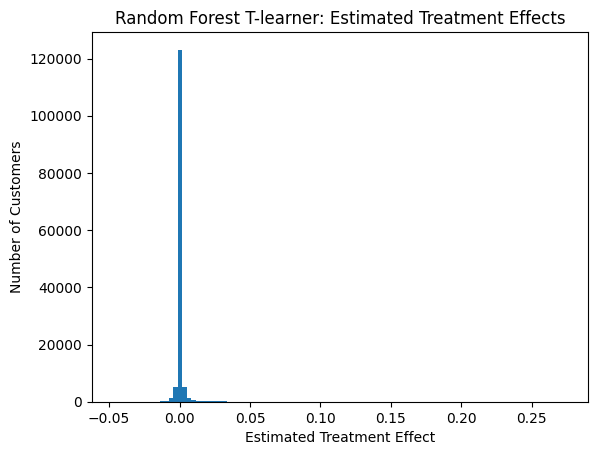

Share of customers with uplift exactly 0: 0.0


In [33]:
plt.hist(rf_ite, bins=100)

plt.xlabel('Estimated Treatment Effect')
plt.ylabel('Number of Customers')
plt.title('Random Forest T-learner: Estimated Treatment Effects')
plt.show()

print('Share of customers with uplift exactly 0:', (rf_ite == 0).mean())

**1.** The estimated treatment effects are concentrated very close to zero for most customers.

**2.** The model also identifies a smaller number of customers with positive or negative treatment effects, with a longer positive tail.

**3.** Although none of the estimates are exactly zero, most are very small.

### 5. Model 2: T-learner with Gradient Boosting (tuned)

* **Histogram Gradient Boosting** builds small trees sequentially, with each tree focusing on the errors of the previous trees. It uses binned feature values to make the tree-building process faster and more memory-efficient, which is useful for my large dataset.
* **Early stopping:** I set aside 10% of the training data for validation and stop adding trees if the model does not improve for 20 consecutive trees. This helps prevent overfitting.
* I tune two parameters:

  * `min_samples_leaf`: the minimum number of customers in each leaf.
  * `max_leaf_nodes`: the maximum number of leaves in each tree; larger values allow more complex trees.

In [34]:
def train_gb_classifier(X, y, min_samples_leaf, max_leaf_nodes):
    model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=500,                 # maximum number of trees
        min_samples_leaf=min_samples_leaf,
        max_leaf_nodes=max_leaf_nodes,
        early_stopping=True,
        validation_fraction=0.1,      # hold back 10% to decide when to stop
        n_iter_no_change=20,          # stop after 20 trees with no improvement
        random_state=42
    )
    model.fit(X, y)
    return model

- The function trains a Gradient Boosting model with specified tree complexity, allows up to 500 trees, and uses early stopping to stop training when additional trees no longer improve the model.

In [35]:
def train_gb_regressor(X, y, min_samples_leaf, max_leaf_nodes):
    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=500,
        min_samples_leaf=min_samples_leaf,
        max_leaf_nodes=max_leaf_nodes,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    )
    model.fit(X, y)
    return model

- This function trains a Gradient Boosting regressor with the same settings. I use it in the X-learner (Section 7) to predict estimated treatment effects, which are continuous values, not 0/1 outcomes.

- Next, I tune the Gradient Boosting models by trying different combinations of `min_samples_leaf` and `max_leaf_nodes`.
    - For each combination, I train separate treatment and control models, calculate predicted uplift on the validation set, and evaluate the results using **Qini AUC**.
    - I use Qini AUC because the goal is to identify customers who are likely to benefit from treatment, rather than simply predict conversions.

In [36]:
validation_data = pd.DataFrame({
    'treatment': T_val,
    'conversion': y_val,
})

tuning_results = []

for leaf_size in [100, 500, 2000]:
    for leaf_nodes in [15, 31]:

        treatment_model = train_gb_classifier(X_train_treatment, y_train_treatment, leaf_size, leaf_nodes)
        control_model = train_gb_classifier(X_train_control, y_train_control, leaf_size, leaf_nodes)

        validation_data['ite'] = (
            treatment_model.predict_proba(X_val)[:, 1]
            - control_model.predict_proba(X_val)[:, 1]
        )

        tuning_results.append({
            'min_samples_leaf': leaf_size,
            'max_leaf_nodes': leaf_nodes,
            'validation_qini_auc': evaluate_model(validation_data, 'ite')['qini_auc'],
        })

tuning_results = pd.DataFrame(tuning_results).sort_values('validation_qini_auc', ascending=False)

tuning_results

,min_samples_leaf,max_leaf_nodes,validation_qini_auc
1,100,31,0.000483
3,500,31,0.000395
2,500,15,0.000296
0,100,15,0.000282
4,2000,15,0.000278
5,2000,31,0.000266


- The combination `min_samples_leaf=100` and `max_leaf_nodes=31` produced the highest validation Qini AUC (**0.000483**) among the settings tested.
- I therefore use these settings for the final Gradient Boosting model.
- The differences between the validation scores are relatively small, so I treat this result as a model-selection choice rather than evidence of a large performance difference.

- Next, I select the combination with the highest validation Qini AUC and save its `min_samples_leaf` and `max_leaf_nodes` values for the final model.

In [37]:
best_settings = tuning_results.iloc[0]

best_leaf_size = int(best_settings['min_samples_leaf'])
best_leaf_nodes = int(best_settings['max_leaf_nodes'])

print('Best min_samples_leaf:', best_leaf_size)
print('Best max_leaf_nodes:', best_leaf_nodes)

Best min_samples_leaf: 100
Best max_leaf_nodes: 31


- Using the best settings from the validation step, I train separate Gradient Boosting models for the treatment and control groups and use their predictions to calculate the estimated treatment effect for each customer in the test set.

In [38]:
gb_treatment_model = train_gb_classifier(X_train_treatment, y_train_treatment, best_leaf_size, best_leaf_nodes)
gb_control_model = train_gb_classifier(X_train_control, y_train_control, best_leaf_size, best_leaf_nodes)

gb_treatment_prediction = gb_treatment_model.predict_proba(X_test)[:, 1]
gb_control_prediction = gb_control_model.predict_proba(X_test)[:, 1]

gb_ite = gb_treatment_prediction - gb_control_prediction

- Next, I calculate ROC AUC separately for the treatment and control models to assess how well each model distinguishes converters from non-converters within its respective group.

In [39]:
gb_treatment_auc = roc_auc_score(y_test[T_test == 1], gb_treatment_prediction[T_test == 1])
gb_control_auc = roc_auc_score(y_test[T_test == 0], gb_control_prediction[T_test == 0])

print('Treatment model AUC:', gb_treatment_auc)
print('Control model AUC:', gb_control_auc)

Treatment model AUC: 0.9569807581075734
Control model AUC: 0.9594226691058687


- Both models have high AUC values (**0.957 for treatment and 0.959 for control**), indicating that they perform well at distinguishing converters from non-converters within their respective groups. Their performance is very similar.

In [40]:
pd.Series(gb_ite).describe()

count    139796.000000
mean          0.001310
std           0.017296
min          -0.675052
25%           0.000022
50%           0.000093
75%           0.000361
max           0.687404
dtype: float64

- The average predicted treatment effect is **0.00131**, or about **0.13 percentage points**, while the median is much smaller at **0.000093**. This indicates that most customers have predicted treatment effects close to zero.
- The model also produces a small number of very large positive and negative predictions, ranging from −0.675 to 0.687. Effects this large are not plausible when only about 0.3% of customers convert. They are most likely noise: the control model is trained on only about 127 converters, so its individual predictions are unreliable. The T-learner then subtracts the control prediction from the treatment prediction, which can amplify this noise.

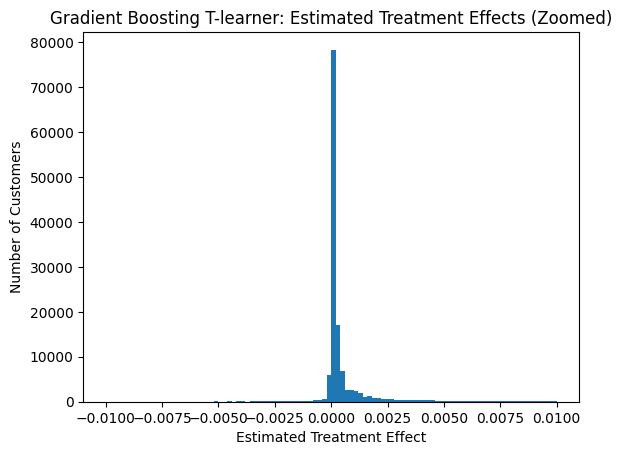

Share outside ±0.01: 0.0394646484877965


In [41]:
plt.hist(gb_ite, bins=100, range=(-0.01, 0.01))
plt.xlabel('Estimated Treatment Effect')
plt.ylabel('Number of Customers')
plt.title('Gradient Boosting T-learner: Estimated Treatment Effects (Zoomed)')
plt.show()

print('Share outside ±0.01:', (np.abs(gb_ite) > 0.01).mean())

### 6. Model 3: S-learner

- The S-learner uses **one** model for all customers, with `treatment` included as an additional feature.
- I make two predictions for each customer, one assuming treatment and one assuming no treatment, and use the difference between these predictions to estimate uplift.

Below, I add `treatment` as an additional feature to the training data and train a single Gradient Boosting model using both treatment and control customers.

In [42]:
X_train_with_treatment = X_train.copy()
X_train_with_treatment['treatment'] = T_train

s_model = train_gb_classifier(X_train_with_treatment, y_train, best_leaf_size, best_leaf_nodes)

For each customer, the S-learner calculates:

**Predicted probability of conversion if treated** − **Predicted probability of conversion if not treated**

which is the estimated individual treatment effect (ITE) for each customer.

In [43]:
X_test_all_treated = X_test.copy()
X_test_all_treated['treatment'] = 1

X_test_all_control = X_test.copy()
X_test_all_control['treatment'] = 0

s_ite = (
    s_model.predict_proba(X_test_all_treated)[:, 1]
    - s_model.predict_proba(X_test_all_control)[:, 1]
)

print('Share of customers with uplift exactly 0:', (s_ite == 0).mean())

Share of customers with uplift exactly 0: 0.0


In [44]:
s_ite = pd.Series(s_ite)

print(s_ite.describe())

count    139796.000000
mean          0.000923
std           0.008273
min          -0.270669
25%           0.000011
50%           0.000027
75%           0.000209
max           0.376230
dtype: float64


- Check for positive and negative uplift.

In [45]:
print('Share with positive uplift:', (s_ite > 0).mean())
print('Share with negative uplift:', (s_ite < 0).mean())

Share with positive uplift: 0.9397121519929039
Share with negative uplift: 0.06028784800709605


1. The S-learner estimates positive uplift for **93.97%** of customers and negative uplift for **6.03%**.
2. However, most estimated effects are very small, with a median uplift of **0.000027**, suggesting that the model predicts little incremental benefit for most customers.

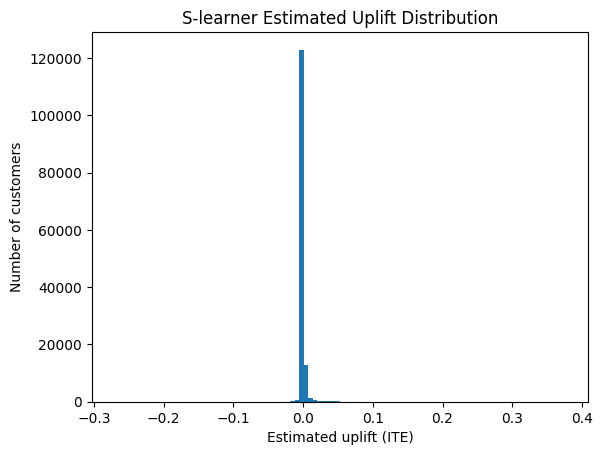

In [46]:
plt.hist(s_ite, bins=100)
plt.xlabel('Estimated uplift (ITE)')
plt.ylabel('Number of customers')
plt.title('S-learner Estimated Uplift Distribution')
plt.show()

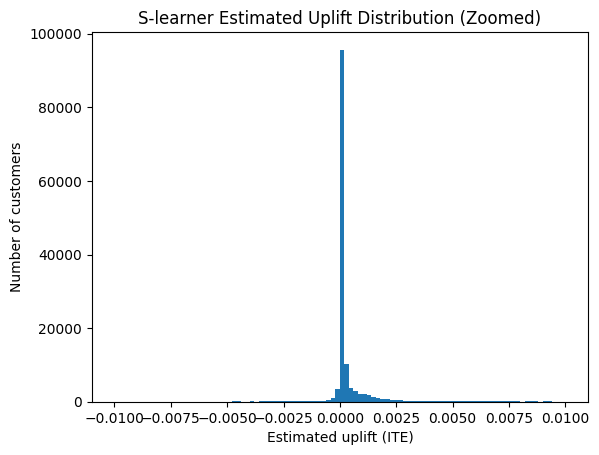

Min / max: -0.2706685605134878 0.37622972561850077
Share exactly zero: 0.0
Share outside ±0.01: 0.021674439898137287
Mean uplift: 0.0009230192615718323
Percentiles (1, 25, 50, 75, 99): [-3.34951127e-03  1.11045271e-05  2.67001333e-05  2.08769495e-04
  1.98214973e-02]


In [47]:
plt.hist(s_ite, bins=100, range=(-0.01, 0.01))
plt.xlabel('Estimated uplift (ITE)')
plt.ylabel('Number of customers')
plt.title('S-learner Estimated Uplift Distribution (Zoomed)')
plt.show()

print("Min / max:", s_ite.min(), s_ite.max())
print("Share exactly zero:", (s_ite == 0).mean())
print("Share outside ±0.01:", (np.abs(s_ite) > 0.01).mean())
print("Mean uplift:", s_ite.mean())
print("Percentiles (1, 25, 50, 75, 99):", np.percentile(s_ite, [1, 25, 50, 75, 99]))

- The S-learner produces mostly small uplift estimates: the median uplift is **0.000027**, while **97.8%** of customers have estimated uplift between −1 and +1 percentage points.
- Only **2.17%** fall outside this range.
- The mean uplift is positive **(0.000923)**, although a small number of extreme predictions drive the range from **−0.271** to **0.376**.

#### Do customers that the model ranks as having higher uplift actually show greater incremental treatment effects?

In [48]:
test_results = X_test.copy()

test_results['treatment'] = T_test
test_results['conversion'] = y_test
test_results['predicted_uplift'] = np.asarray(s_ite)

Next, I divide customers into ten equal groups (deciles) by predicted uplift, from Decile 1 (highest) to Decile 10 (lowest), and compare the observed treated and control conversion rates within each group. I rank the scores before cutting them, so customers with tied scores are still split evenly across deciles. I use the same function for the baseline in Section 8.

In [49]:
def decile_table(data, score_column):
    data = data.copy()

    # Rank first so that tied scores do not break the decile cut
    ranks = data[score_column].rank(method='first')
    data['decile'] = 10 - pd.qcut(ranks, 10, labels=False)

    treated_rate = data[data['treatment'] == 1].groupby('decile')['conversion'].mean()
    control_rate = data[data['treatment'] == 0].groupby('decile')['conversion'].mean()

    table = pd.DataFrame({
        'treated_conversion': treated_rate,
        'control_conversion': control_rate
    })
    table['observed_uplift'] = table['treated_conversion'] - table['control_conversion']

    return table

In [50]:
decile_table(test_results, 'predicted_uplift')

,treated_conversion,control_conversion,observed_uplift
decile,,,
1,0.023485,0.015544,0.007941
2,0.001848,0.001931,-0.000083
3,0.001011,0.000474,0.000537
4,0.000254,0.000000,0.000254
5,0.000085,0.000000,0.000085
6,0.000084,0.000000,0.000084
7,0.000254,0.000000,0.000254
8,0.000000,0.000000,0.000000
9,0.000000,0.000000,0.000000


* **Decile 1:** Observed uplift is 0.79 percentage points, about seven times the overall average of 0.11. It accounts for roughly 70% of all incremental conversions in the test set. These figures are uncertain: each decile has only about 2,100 control customers, so the control rate in decile 1 rests on roughly 30 converters. The exact size of the uplift should be read as approximate.

* **Deciles 2–9:** Observed uplift is close to zero, and conversion rates in both groups are very low. The model separates the top decile from the rest but does not distinguish well within the remaining deciles.

* **Decile 10:** These are the 10% of customers with the lowest predicted uplift. Only about 6% of all customers have a negative prediction, so this decile also contains customers with small positive predictions. Observed uplift here is slightly positive (0.06 percentage points), and conversion rates are higher than in deciles 2–9. So the low and negative predictions do not correspond to customers who are actually harmed by the ad.


### 7. Model 4: X-learner

The X-learner is designed for situations where the treatment and control groups are very different in size, as in this dataset (about 85% treated and 15% control). It builds on the two gradient boosting models from Model 2.

**Step 1. Estimate each training customer's individual treatment effect:**

* For a **treated** customer: actual outcome − outcome predicted by the control model.
* For a **control** customer: outcome predicted by the treatment model − actual outcome.

**Step 2.** Train a separate regression model for each group to predict these estimated treatment effects using the customer features.

**Step 3.** Combine the predictions from the two regression models using a weighted average to obtain the final estimated treatment effect.

In [51]:
# Step 1: estimate individual effects in the training data
treated_effects = y_train_treatment - gb_control_model.predict_proba(X_train_treatment)[:, 1]

control_effects = gb_treatment_model.predict_proba(X_train_control)[:, 1] - y_train_control

In [52]:
# Step 2: learn to predict these effects from the features
effect_model_treated = train_gb_regressor(X_train_treatment, treated_effects, best_leaf_size, best_leaf_nodes)

effect_model_control = train_gb_regressor(X_train_control, control_effects, best_leaf_size, best_leaf_nodes)

In Step 3, the weight is based on the share of customers in each group. Here, about 85% of customers were treated and 15% were in the control group.

* The final estimate is 0.85 × (effect model trained on control customers) + 0.15 × (effect model trained on treated customers).
* The control effect model gets the larger weight because of how its targets were built. For each control customer, the estimated effect uses a prediction from the treatment model, which was trained on about 357,000 treated customers. These targets are therefore fairly reliable. The treated effect model’s targets use the control model, which was trained on far fewer customers and only about 127 converters, so they are noisier.

In [53]:
# Step 3: weighted average of the two predictions
weight = T_train.mean()

x_ite = (
    weight * effect_model_control.predict(X_test)
    + (1 - weight) * effect_model_treated.predict(X_test)
)

pd.Series(x_ite).describe()

count    139796.000000
mean          0.000858
std           0.007480
min          -0.101401
25%           0.000195
50%           0.000217
75%           0.000319
max           0.168661
dtype: float64

- The final X-learner estimate is mostly based on the effect model trained on control customers, with a smaller contribution from the effect model trained on treated customers.
- The X-learner produces mostly small estimated treatment effects. The mean ITE is 0.000858 (about 0.086 percentage points), while the median is 0.000217 (about 0.022 percentage points). The middle 50% of customers have estimated uplift between 0.020 and 0.032 percentage points. A small number of customers have much larger positive or negative estimates, resulting in a range from −0.101 to 0.169.


In [54]:
positive_share = (x_ite > 0).mean()
negative_share = (x_ite < 0).mean()
zero_share = (x_ite == 0).mean()

print("Positive uplift:", positive_share)
print("Negative uplift:", negative_share)
print("Zero uplift:", zero_share)

Positive uplift: 0.9225800452087327
Negative uplift: 0.07741995479126727
Zero uplift: 0.0


- The X-learner predicts positive uplift for 92.26% of customers and negative uplift for 7.74%.
- However, most estimates are very close to zero (the median is about 0.02 percentage points), so the sign alone says little. For most customers, the model predicts almost no effect rather than a clear benefit or harm.
- I do not interpret the negative predictions as evidence that the ad harms some customers. In Section 6, the customers with the lowest predicted uplift from the S-learner did not show negative observed uplift.

### 8. Comparing All Models on the Test Set

I also include a **baseline** that ranks customers by how likely they are to convert if treated. This represents the traditional **“target people most likely to buy”** approach that my research question seeks to evaluate against.

* If the uplift models do not outperform this baseline, then uplift modeling may not provide additional value for targeting.

In [55]:
results = pd.DataFrame({
    'treatment': T_test.to_numpy(),
    'conversion': y_test.to_numpy(),
    'baseline': np.asarray(gb_treatment_prediction),
    'rf_t_learner': np.asarray(rf_ite),
    'gb_t_learner': np.asarray(gb_ite),
    's_learner': np.asarray(s_ite),
    'x_learner': np.asarray(x_ite)
})

results.head()

model_columns = [
    'baseline',
    'rf_t_learner',
    'gb_t_learner',
    's_learner',
    'x_learner'
]

This DataFrame combines the test-set treatment and conversion outcomes with the predictions from the baseline and four uplift models. This allows us to compare how well each approach identifies customers who are likely to benefit from treatment.

As a sanity check, I compare each model’s average predicted effect with the observed average effect in the test set. If a model is reasonable overall, these two values should be similar.

In [56]:
treated_rate = results.loc[results['treatment'] == 1, 'conversion'].mean()
control_rate = results.loc[results['treatment'] == 0, 'conversion'].mean()

print('Observed average effect in the test set:', treated_rate - control_rate)
print(results[model_columns[1:]].mean())

Observed average effect in the test set: 0.0011445980799229239
rf_t_learner    0.000906
gb_t_learner    0.001310
s_learner       0.000923
x_learner       0.000858
dtype: float64


The observed average effect is 0.11 percentage points. The models’ average predictions range from 0.09 to 0.13, suggesting that their overall estimates are reasonable, even though individual predictions may be noisy.

- Each cell below shows the estimate followed by its 95% confidence interval in brackets.

In [57]:
comparison = {}

for model in model_columns:
    comparison[model] = evaluate_with_intervals(results, model)

comparison = pd.DataFrame(comparison).T

comparison

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
baseline,"0.0004 [0.0001, 0.0006]","0.0093 [-0.0053, 0.0211]","0.0080 [0.0004, 0.0143]","0.0047 [0.0008, 0.0075]","0.0032 [0.0007, 0.0053]","0.0022 [0.0007, 0.0034]"
rf_t_learner,"0.0001 [-0.0002, 0.0004]","0.0058 [-0.0089, 0.0180]","0.0050 [-0.0023, 0.0115]","0.0031 [-0.0008, 0.0062]","0.0024 [-0.0001, 0.0044]","0.0016 [0.0002, 0.0028]"
gb_t_learner,"0.0002 [-0.0000, 0.0005]","0.0126 [0.0009, 0.0237]","0.0075 [0.0016, 0.0128]","0.0041 [0.0012, 0.0069]","0.0028 [0.0007, 0.0049]","0.0018 [0.0006, 0.0031]"
s_learner,"0.0003 [0.0001, 0.0006]","0.0142 [0.0006, 0.0244]","0.0079 [0.0012, 0.0131]","0.0042 [0.0012, 0.0069]","0.0031 [0.0010, 0.0047]","0.0021 [0.0008, 0.0031]"
x_learner,"0.0002 [-0.0001, 0.0005]","0.0082 [-0.0042, 0.0199]","0.0078 [0.0018, 0.0135]","0.0036 [0.0005, 0.0064]","0.0025 [0.0007, 0.0044]","0.0018 [0.0005, 0.0029]"


The baseline has the highest estimated Qini AUC. The S-learner has the highest estimated uplift at 5%, followed by the Gradient Boosting T-learner.

* The confidence intervals are wide and overlap across the models, so this table alone does not show whether any model is better than the baseline. I test this directly below.


- Each cell shows the difference between the model's metric and the baseline, with a 95% confidence interval.

In [58]:
differences_from_baseline = {}

for model in model_columns[1:]:   # skip the baseline itself
    differences_from_baseline[model] = compare_to_baseline(results, model)

pd.DataFrame(differences_from_baseline).T

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
rf_t_learner,"-0.0002 [-0.0004, -0.0001]","-0.0034 [-0.0075, 0.0014]","-0.0030 [-0.0054, -0.0006]","-0.0016 [-0.0026, -0.0003]","-0.0008 [-0.0015, 0.0001]","-0.0006 [-0.0010, -0.0001]"
gb_t_learner,"-0.0001 [-0.0004, 0.0002]","0.0033 [-0.0038, 0.0122]","-0.0005 [-0.0039, 0.0040]","-0.0005 [-0.0021, 0.0018]","-0.0004 [-0.0015, 0.0012]","-0.0003 [-0.0010, 0.0005]"
s_learner,"-0.0000 [-0.0003, 0.0003]","0.0049 [-0.0022, 0.0123]","-0.0001 [-0.0035, 0.0036]","-0.0004 [-0.0020, 0.0014]","-0.0001 [-0.0009, 0.0011]","-0.0001 [-0.0007, 0.0005]"
x_learner,"-0.0002 [-0.0004, 0.0001]","-0.0011 [-0.0071, 0.0077]","-0.0003 [-0.0039, 0.0040]","-0.0011 [-0.0027, 0.0010]","-0.0007 [-0.0016, 0.0008]","-0.0004 [-0.0010, 0.0003]"


No uplift model clearly outperforms the baseline. For the Gradient Boosting T-learner, S-learner, and X-learner, every 95% interval for the difference from the baseline includes 0, so they are not clearly different from simply ranking customers by their likelihood of conversion.

* The S-learner and Gradient Boosting T-learner have higher estimated uplift than the baseline in the top 5% (by 0.49 and 0.33 percentage points, respectively), but the intervals include 0, so this is not strong evidence of better targeting.
* The Random Forest T-learner performs worse than the baseline on some metrics: its intervals are entirely below 0 for Qini AUC and uplift at 10%, 20%, and 50%. 


- The plot shows the Qini curve for each model.

- The dashed line represents random targeting. A model with better targeting performance will have a curve that rises faster and stays further above the dashed line.

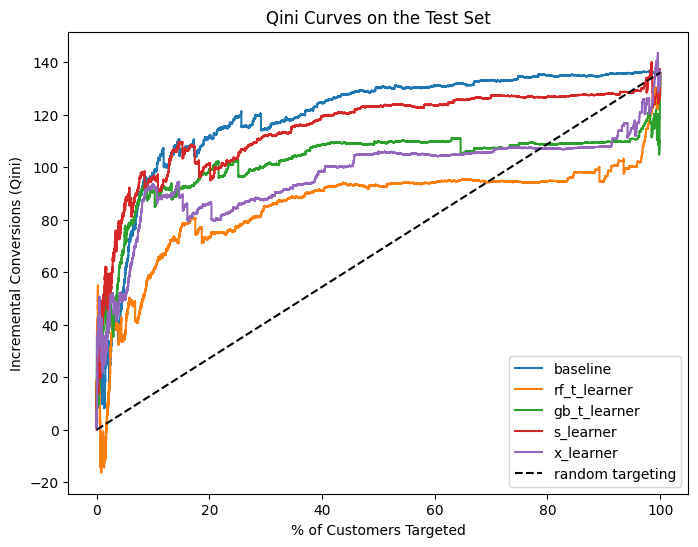

In [59]:
plt.figure(figsize=(8, 6))

for model in model_columns:
    curve = uplift_curve(results, model)
    plt.plot(curve['fraction_targeted'] * 100, curve['qini'], label=model)

baseline_curve = uplift_curve(results, 'baseline')
final_qini = baseline_curve['qini'].iloc[-1]
plt.plot([0, 100], [0, final_qini], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves on the Test Set')
plt.legend()
plt.show()

Most of the difference between the models is among the highest-ranked customers, which is hard to see in the full plot. The plot below shows the same curves for the top 20% only.

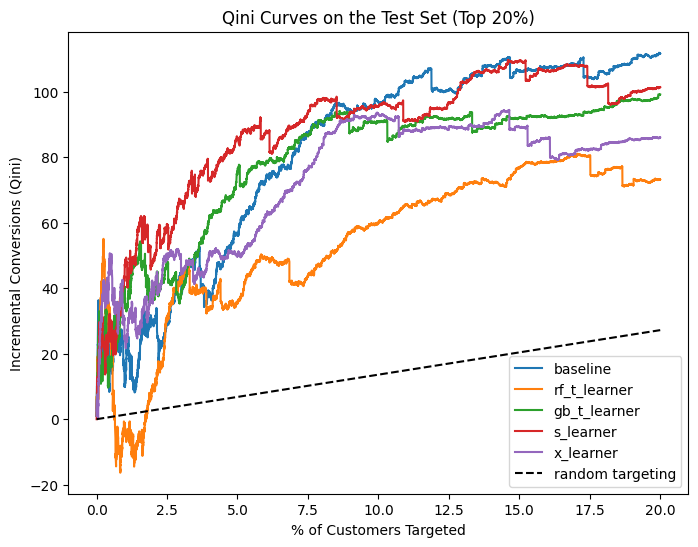

In [60]:
plt.figure(figsize=(8, 6))

for model in model_columns:
    curve = uplift_curve(results, model)
    top = curve[curve['fraction_targeted'] <= 0.20]
    plt.plot(top['fraction_targeted'] * 100, top['qini'], label=model)

plt.plot([0, 20], [0, final_qini * 0.20], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves on the Test Set (Top 20%)')
plt.legend()
plt.show()

All models perform well above random targeting. The S-learner and Gradient Boosting T-learner are ahead of the baseline for roughly the first 7% of customers, after which the baseline catches up and leads. The Random Forest T-learner remains below the other models throughout.

To see where the campaign's effect is concentrated, I split the test customers into ten equal groups by score and compare treated and control conversion rates in each. Decile 1 contains the customers with the highest scores. I do this for the baseline so I can compare it with the S-learner results in Section 6.

In [61]:
decile_table(results, 'baseline')

,treated_conversion,control_conversion,observed_uplift
decile,,,
1,0.027419,0.019392,0.008027
2,0.002092,0.001481,0.000611
3,0.000674,0.000947,-0.000273
4,0.000423,0.000000,0.000423
5,0.000085,0.000000,0.000085
6,0.000084,0.000000,0.000084
7,0.000084,0.000000,0.000084
8,0.000168,0.000000,0.000168
9,0.000000,0.000000,0.000000


The baseline shows a similar pattern to the S-learner: decile 1 has an observed uplift of 0.80 percentage points (compared with 0.79 for the S-learner), while the other deciles are close to zero.

As with the S-learner, decile 1 contains only about 2,100 control customers (roughly 40 converters), so the 0.80 figure is approximate.

Finally, I check the control conversion rate for the top 10% selected by each model, i.e., how often they convert without the ad.

* If the control conversion rate is as high as the baseline's, the model may just be finding people who would have converted anyway.

In [62]:
top_10_check = []

for model in model_columns:
    curve = uplift_curve(results, model)
    row = curve.iloc[int(len(curve) * 0.10) - 1]

    top_10_check.append({
        'model': model,
        'control conversion rate (top 10%)': row['control_rate'],
        'treated conversion rate (top 10%)': row['treated_rate'],
    })

pd.DataFrame(top_10_check).set_index('model').round(4)

,control conversion rate (top 10%),treated conversion rate (top 10%)
model,,
baseline,0.0194,0.0274
rf_t_learner,0.0185,0.0234
gb_t_learner,0.0134,0.0209
s_learner,0.0155,0.0235
x_learner,0.0136,0.0213


The uplift models have lower control conversion rates in their top 10% than the baseline (1.34%–1.85% vs. 1.94%), so they select fewer customers who would have converted without the ad. However, their treated conversion rates are also lower (2.09%–2.35% vs. 2.74%). As a result, their observed uplift is no higher than the baseline's: 0.80 percentage points for the baseline, compared with 0.50–0.79 percentage points for the uplift models. Selecting different customers did not produce more incremental conversions.

### 9. Conclusion

**Research question:** given a fixed budget, should customers be targeted by predicted uplift rather than by how likely they are to buy?

**1.** Uplift models did not beat the simple baseline. Ranking customers by their predicted conversion probability if treated performed as well as any of the four uplift models. For the Gradient Boosting T-learner, S-learner and X-learner, every 95% interval for the difference from the baseline includes 0, on Qini AUC and on uplift at 5%, 10%, 20%, 30% and 50%. The Random Forest T-learner was worse than the baseline on several metrics. The S-learner and Gradient Boosting T-learner had higher point estimates in the top 5%, but the intervals are too wide to treat this as a real advantage.

**2.** The campaign effect is concentrated in a small group. For both the baseline and the S-learner, the top 10% of customers show an observed uplift of about 0.8 percentage points, compared with 0.11 on average. The remaining 90% show uplift close to zero. With a limited budget, the most useful step is to target that top group. A simple conversion model already finds it.

**3.** Uplift models choose different customers, not better ones. In their top 10%, the uplift models select customers who are less likely to convert without the ad than the baseline’s picks. But those customers are also less likely to convert with the ad, so the incremental conversions are no higher.

**4.** The effect of seeing the ad must come from the randomized comparison. Exposure was not random: the features predict it with an AUC of 0.92, and exposed customers would have converted more often even without the ad. Matching on the features still overstates the effect (4.89 vs. 3.13 percentage points), so exposure depends on things the features do not record. The randomized estimate of about 3.1 percentage points is the more reliable one.

**Limitations:**

1. The intervals only reflect test-set sampling, not retraining variation.
2. Conversions are rare, especially in the control group, so per-decile results rest on a few dozen converters.
3. Results come from a 5% sample of the Criteo data and may differ on the full dataset.
4. Only conversion was studied as the outcome.